<a href="https://colab.research.google.com/github/english075social/Clase80/blob/main/Clasificacion_cultivos_v2_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌱 Clasificación multiclase de cultivos agrícolas (AgroTech Verde)

**Autores:** Luis · Karen · Milena | Fundación Somos F5

## Objetivo
Recomendar **qué cultivo sembrar** en una parcela a partir de las características de su suelo
(nitrógeno, fósforo, potasio, pH) y de su clima (temperatura, humedad, lluvia).

Es un problema de **clasificación multiclase**: hay 22 cultivos posibles y cada parcela pertenece a uno solo.

## Dataset
**Crop Recommendation Dataset** (Kaggle) · 2.200 filas · 8 columnas · 22 cultivos (100 parcelas de cada uno).

## Flujo del proyecto
1. Cargar los datos
2. Revisar su calidad (nulos, duplicados)
3. Análisis exploratorio (EDA)
4. Preparar los datos para el modelo
5. Crear un modelo de referencia ("adivinar al azar")
6. Entrenar Árbol de Decisión y Random Forest
7. Evaluar y comparar
8. Interpretar y usar el modelo

## 1. Librerías

In [1]:
# pandas: tablas de datos (como Excel / Power Query)
import pandas as pd
# numpy: cálculos numéricos
import numpy as np
# matplotlib y seaborn: gráficos (como las visualizaciones de Power BI)
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de machine learning de scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyClassifier            # modelo "tonto" que sirve de referencia
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Estilo de los gráficos
sns.set_theme(style="whitegrid")

## 2. Carga de datos

Descarga `Crop_recommendation.csv` desde Kaggle y guárdalo **en la misma carpeta que este notebook**.

In [2]:
# read_csv lee un archivo CSV y lo convierte en una tabla (DataFrame)
df = pd.read_csv("Crop_recommendation.csv")

# .shape devuelve (filas, columnas)
print("Filas y columnas:", df.shape)

# .head() muestra las 5 primeras filas
df.head()

Filas y columnas: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


### Traducir columnas y cultivos al español

Usamos **diccionarios**: pares `"nombre original": "nombre nuevo"`.
Funciona como una tabla de equivalencias o un BUSCARV en Excel.

In [3]:
# Diccionario para renombrar columnas: a la izquierda el nombre actual, a la derecha el nuevo
nombres_columnas = {
    "N": "nitrogeno",
    "P": "fosforo",
    "K": "potasio",
    "temperature": "temperatura",
    "humidity": "humedad",
    "ph": "ph",
    "rainfall": "lluvia",
    "label": "cultivo",
}
df = df.rename(columns=nombres_columnas)

# Diccionario para traducir el nombre de cada cultivo
traduccion_cultivos = {
    "apple": "Manzana", "banana": "Plátano", "blackgram": "Frijol negro",
    "chickpea": "Garbanzo", "coconut": "Coco", "coffee": "Café",
    "cotton": "Algodón", "grapes": "Uva", "jute": "Yute",
    "kidneybeans": "Judía roja", "lentil": "Lenteja", "maize": "Maíz",
    "mango": "Mango", "mothbeans": "Judía polilla", "mungbean": "Judía mungo",
    "muskmelon": "Melón", "orange": "Naranja", "papaya": "Papaya",
    "pigeonpeas": "Guandú", "pomegranate": "Granada", "rice": "Arroz",
    "watermelon": "Sandía",
}
# .map() sustituye cada valor por su traducción (como un BUSCARV)
df["cultivo"] = df["cultivo"].map(traduccion_cultivos)

df.head()

,nitrogeno,fosforo,potasio,temperatura,humedad,ph,lluvia,cultivo
0,90,42,43,20.879744,82.002744,6.502985,202.935536,Arroz
1,85,58,41,21.770462,80.319644,7.038096,226.655537,Arroz
2,60,55,44,23.004459,82.320763,7.840207,263.964248,Arroz
3,74,35,40,26.491096,80.158363,6.980401,242.864034,Arroz
4,78,42,42,20.130175,81.604873,7.628473,262.717340,Arroz


| Columna | Significado | Unidad |
|---|---|---|
| nitrogeno, fosforo, potasio | Nutrientes del suelo (NPK) | proporción |
| temperatura | Temperatura media | °C |
| humedad | Humedad relativa | % |
| ph | Acidez del suelo | 0–14 |
| lluvia | Precipitación | mm |
| **cultivo** | **Lo que queremos predecir** | 22 clases |

## 3. Calidad de los datos

In [4]:
# .info() muestra el tipo de cada columna y cuántos valores no vacíos tiene
df.info()

# Nulos por columna (como contar celdas vacías en Excel)
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Filas duplicadas
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   nitrogeno    2200 non-null   int64  
 1   fosforo      2200 non-null   int64  
 2   potasio      2200 non-null   int64  
 3   temperatura  2200 non-null   float64
 4   humedad      2200 non-null   float64
 5   ph           2200 non-null   float64
 6   lluvia       2200 non-null   float64
 7   cultivo      2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB

Valores nulos por columna:
nitrogeno      0
fosforo        0
potasio        0
temperatura    0
humedad        0
ph             0
lluvia         0
cultivo        0
dtype: int64

Filas duplicadas: 0


In [5]:
# Estadísticas básicas: media, mínimo, máximo, cuartiles
df.describe().round(2)

,nitrogeno,fosforo,potasio,temperatura,humedad,ph,lluvia
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


In [6]:
# ¿Cuántas parcelas hay de cada cultivo? Si hay muchas más de uno que de otro, hablamos de desbalanceo
print(df["cultivo"].value_counts())

cultivo
Arroz            100
Maíz             100
Garbanzo         100
Judía roja       100
Guandú           100
Judía polilla    100
Judía mungo      100
Frijol negro     100
Lenteja          100
Granada          100
Plátano          100
Mango            100
Uva              100
Sandía           100
Melón            100
Manzana          100
Naranja          100
Papaya           100
Coco             100
Algodón          100
Yute             100
Café             100
Name: count, dtype: int64


## 4. Análisis exploratorio (EDA)

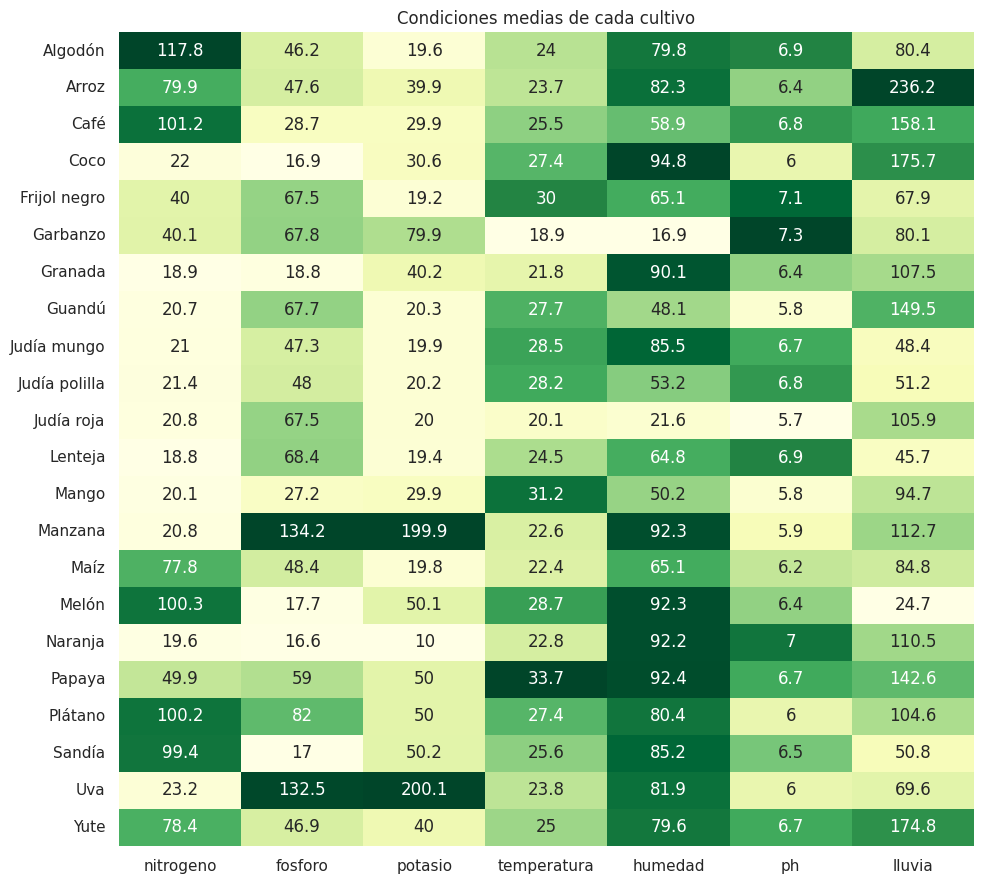

In [7]:
# Media de cada variable por cultivo: equivale a una tabla dinámica de Excel
medias_por_cultivo = df.groupby("cultivo").mean().round(1)

plt.figure(figsize=(10, 9))
# Normalizamos cada columna (0 a 1) solo para colorear; los números mostrados son los reales
normalizado = (medias_por_cultivo - medias_por_cultivo.min()) / (medias_por_cultivo.max() - medias_por_cultivo.min())
sns.heatmap(normalizado, annot=medias_por_cultivo, fmt="g", cmap="YlGn", cbar=False)
plt.title("Condiciones medias de cada cultivo")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Qué buscar:** si los cultivos tienen condiciones muy distintas entre sí, el modelo podrá diferenciarlos.
Por ejemplo, el arroz destaca por la lluvia y la manzana y la uva por el fósforo y el potasio.

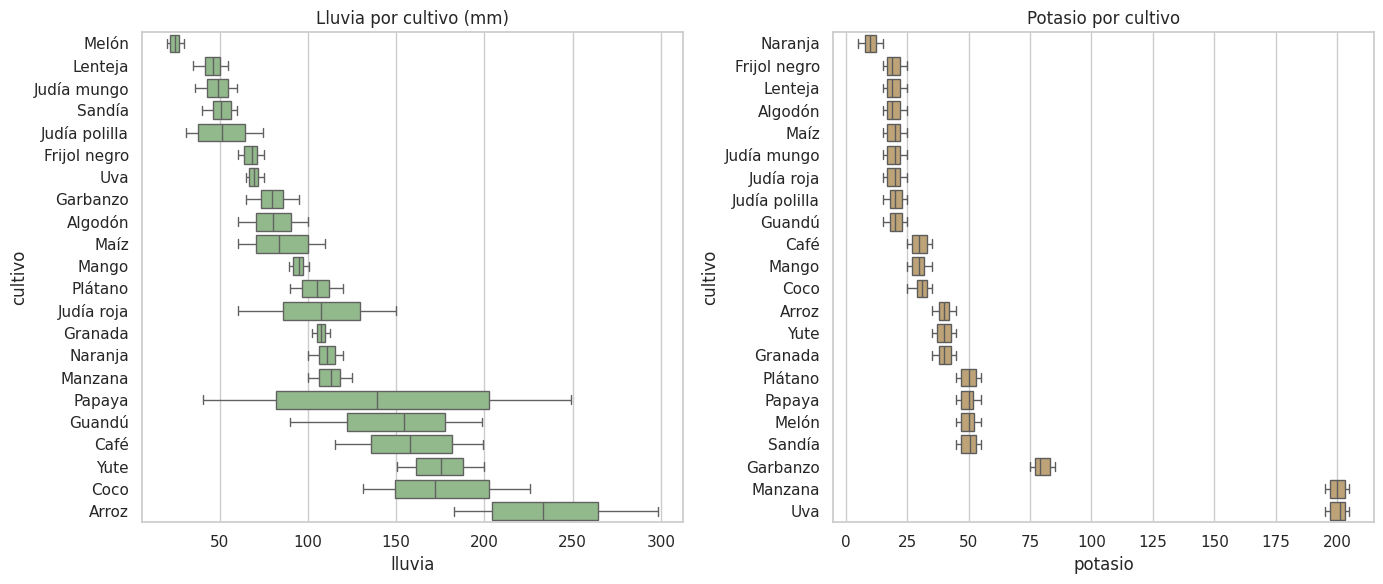

In [8]:
# Boxplot: muestra cómo se reparte una variable en cada cultivo
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
orden = medias_por_cultivo["lluvia"].sort_values().index
sns.boxplot(data=df, y="cultivo", x="lluvia", order=orden, ax=ejes[0], color="#8cc084")
ejes[0].set_title("Lluvia por cultivo (mm)")
orden = medias_por_cultivo["potasio"].sort_values().index
sns.boxplot(data=df, y="cultivo", x="potasio", order=orden, ax=ejes[1], color="#c9a66b")
ejes[1].set_title("Potasio por cultivo")
plt.tight_layout()
plt.show()

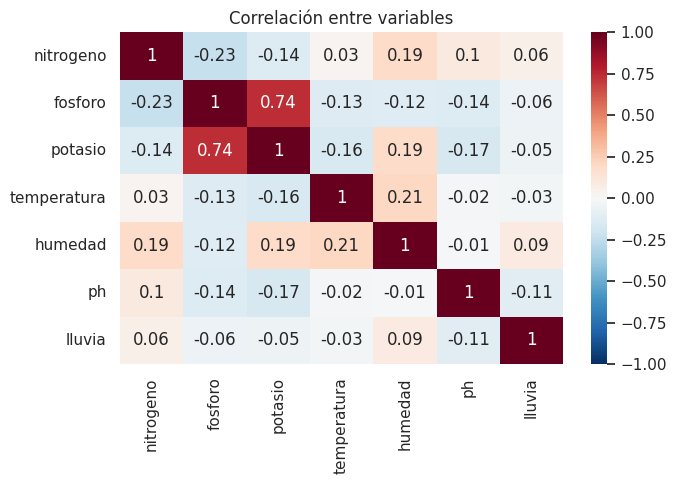

In [9]:
# Correlación entre variables numéricas (de -1 a 1)
plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns="cultivo").corr().round(2), annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.tight_layout()
plt.show()

**Lectura:** fósforo y potasio están muy relacionados (≈0,74). El resto de variables son bastante independientes,
así que cada una aporta información distinta.

## 5. Preparación de los datos

In [10]:
# X = las pistas (todas las columnas menos el cultivo)
X = df.drop(columns="cultivo")
# y = la respuesta que queremos predecir
y = df["cultivo"]

# 80% para entrenar, 20% para el examen final
# stratify=y garantiza que cada cultivo tenga la misma proporción en los dos grupos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (1760, 7) | Prueba: (440, 7)


> **No escalamos los datos** (sin `StandardScaler`): los árboles comparan valores con umbrales
> ("¿lluvia > 150?"), así que la escala de cada variable no les afecta.

## 6. Modelo de referencia (baseline)

Antes de entrenar nada, medimos cuánto acertaría alguien que **adivina siempre lo mismo**.
Con 22 cultivos equilibrados, ronda el 4,5 %. Cualquier modelo útil tiene que superarlo con claridad.

In [11]:
modelo_referencia = DummyClassifier(strategy="most_frequent")
modelo_referencia.fit(X_train, y_train)
acierto_referencia = accuracy_score(y_test, modelo_referencia.predict(X_test))
print(f"Acierto del modelo de referencia: {acierto_referencia:.2%}")

Acierto del modelo de referencia: 4.55%


## 7. Entrenamiento de los modelos

### ¿Cuántos niveles de preguntas necesita el árbol?
Con 22 cultivos, un árbol muy corto no tiene "preguntas" suficientes para separarlos todos.
Probamos varias profundidades con validación cruzada (explicada más abajo) y elegimos la más pequeña que funcione bien.

In [12]:
for profundidad in [4, 6, 8, 10, 12]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    nota = cross_val_score(arbol, X_train, y_train, cv=5).mean()
    print(f"Profundidad {profundidad:>2}: {nota:.2%}")

Profundidad  4: 31.82%
Profundidad  6: 49.72%
Profundidad  8: 80.57%
Profundidad 10: 97.90%
Profundidad 12: 98.75%


A partir de 10 niveles la mejora es mínima, así que usamos `max_depth=10`.

In [13]:
# MODELO 1: Árbol de Decisión, limitado a 10 niveles de preguntas para evitar que memorice
modelo_arbol = DecisionTreeClassifier(max_depth=10, random_state=42)
modelo_arbol.fit(X_train, y_train)

# MODELO 2: Random Forest, 100 árboles que votan
modelo_bosque = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_bosque.fit(X_train, y_train)

# Predicciones sobre el examen final
pred_arbol = modelo_arbol.predict(X_test)
pred_bosque = modelo_bosque.predict(X_test)

resultados = pd.DataFrame({
    "Modelo": ["Referencia (azar)", "Árbol de Decisión", "Random Forest"],
    "Acierto": [acierto_referencia, accuracy_score(y_test, pred_arbol), accuracy_score(y_test, pred_bosque)],
})
resultados["Acierto"] = (resultados["Acierto"] * 100).round(2)
resultados

,Modelo,Acierto
0,Referencia (azar),4.55
1,Árbol de Decisión,96.82
2,Random Forest,100.00


### Validación cruzada

Un solo examen puede salir bien o mal por suerte. La **validación cruzada** repite el examen 5 veces
con trozos distintos de los datos y da la media: es una nota más fiable.

In [ ]:
for nombre, modelo in [("Árbol de Decisión", modelo_arbol), ("Random Forest", modelo_bosque)]:
    notas = cross_val_score(modelo, X, y, cv=5, scoring="accuracy")
    print(f"{nombre:<18}: media {notas.mean():.2%}  (±{notas.std():.2%})")

Árbol de Decisión : media 97.68%  (±0.83%)
Random Forest     : media 99.50%  (±0.36%)


## 8. Evaluación detallada del mejor modelo (Random Forest)

In [14]:
# Precision, recall y F1 por cultivo
print(classification_report(y_test, pred_bosque, digits=3))

               precision    recall  f1-score   support

      Algodón      1.000     1.000     1.000        20
        Arroz      1.000     1.000     1.000        20
         Café      1.000     1.000     1.000        20
         Coco      1.000     1.000     1.000        20
 Frijol negro      1.000     1.000     1.000        20
     Garbanzo      1.000     1.000     1.000        20
      Granada      1.000     1.000     1.000        20
       Guandú      1.000     1.000     1.000        20
  Judía mungo      1.000     1.000     1.000        20
Judía polilla      1.000     1.000     1.000        20
   Judía roja      1.000     1.000     1.000        20
      Lenteja      1.000     1.000     1.000        20
        Mango      1.000     1.000     1.000        20
      Manzana      1.000     1.000     1.000        20
         Maíz      1.000     1.000     1.000        20
        Melón      1.000     1.000     1.000        20
      Naranja      1.000     1.000     1.000        20
       Pa

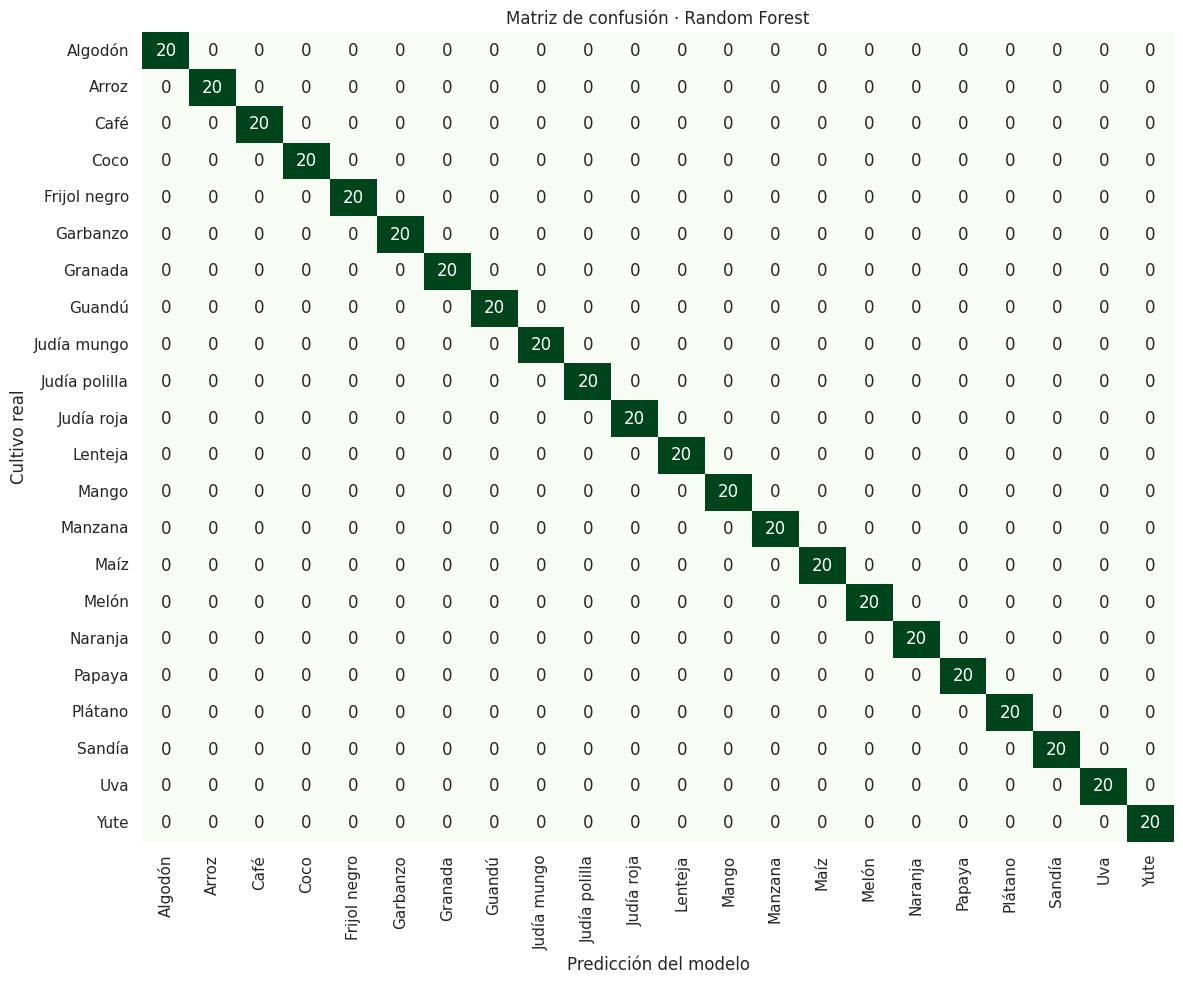

In [15]:
# Matriz de confusión: filas = cultivo real, columnas = predicción. La diagonal son los aciertos
matriz = confusion_matrix(y_test, pred_bosque, labels=modelo_bosque.classes_)
plt.figure(figsize=(12, 10))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=modelo_bosque.classes_, yticklabels=modelo_bosque.classes_)
plt.title("Matriz de confusión · Random Forest")
plt.xlabel("Predicción del modelo")
plt.ylabel("Cultivo real")
plt.tight_layout()
plt.show()

In [16]:
# Listar solo los errores para ver qué cultivos se confunden
errores = pd.DataFrame({"real": y_test, "prediccion": pred_bosque})
errores = errores[errores["real"] != errores["prediccion"]]
print(f"Errores: {len(errores)} de {len(y_test)}")
errores.value_counts().reset_index(name="veces")

Errores: 0 de 440


,real,prediccion,veces


## 9. Importancia de las variables

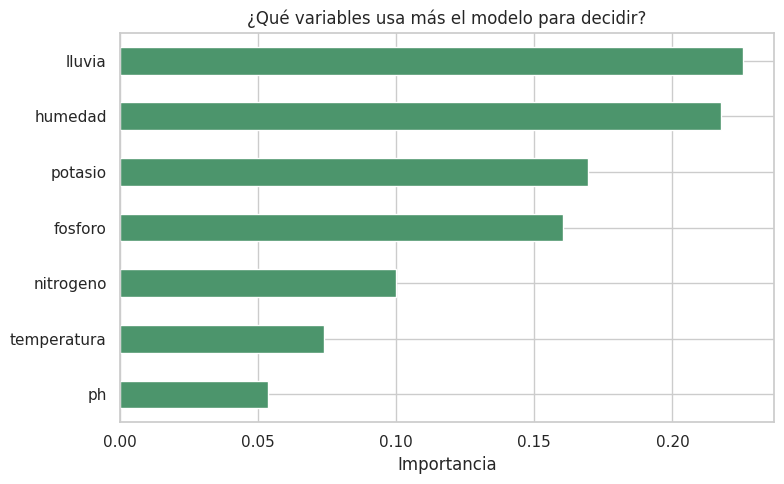

lluvia         22.6 %
humedad        21.8 %
potasio        16.9 %
fosforo        16.0 %
nitrogeno      10.0 %
temperatura     7.4 %
ph              5.4 %
dtype: object


In [17]:
importancias = pd.Series(modelo_bosque.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
importancias.plot(kind="barh", color="#4c956c")
plt.title("¿Qué variables usa más el modelo para decidir?")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

print((importancias.sort_values(ascending=False) * 100).round(1).astype(str) + " %")

## 10. Usar el modelo con una parcela nueva

In [18]:
# Una parcela inventada: escribimos sus valores en un diccionario y la convertimos en tabla de 1 fila
parcela_nueva = pd.DataFrame([{
    "nitrogeno": 85, "fosforo": 45, "potasio": 40,
    "temperatura": 23.5, "humedad": 82.0, "ph": 6.4, "lluvia": 210.0,
}])

recomendacion = modelo_bosque.predict(parcela_nueva)[0]
print("Cultivo recomendado:", recomendacion)

# Top 3 cultivos más probables
probabilidades = pd.Series(modelo_bosque.predict_proba(parcela_nueva)[0], index=modelo_bosque.classes_)
print("\nTop 3:")
print((probabilidades.sort_values(ascending=False).head(3) * 100).round(1).astype(str) + " %")

Cultivo recomendado: Arroz

Top 3:
Arroz     92.0 %
Yute       7.0 %
Papaya     1.0 %
dtype: object


## 11. Conclusiones

1. **El modelo funciona:** Random Forest acierta un ~99,5 % en validación cruzada (100 % en el examen final),
   frente al 4,5 % de adivinar al azar. El Árbol de Decisión se queda en torno al 97–98 %.
2. **Random Forest es la mejor opción:** es más estable que un único árbol porque combina el voto de 100 árboles.
3. **Las variables que más deciden son la lluvia y la humedad**, seguidas del potasio y el fósforo.
   El pH y la temperatura aportan menos, porque muchos cultivos toleran rangos parecidos.
4. **Limitación importante:** un acierto tan alto indica que el dataset es muy "limpio" (probablemente
   generado o seleccionado para enseñar). En datos de campo reales esperaríamos resultados más bajos,
   por lo que antes de usarlo en producción habría que validarlo con parcelas reales.

## Próximos pasos
- Validar el modelo con datos reales de parcelas.
- Probar el modelo sin fósforo o potasio (están correlacionados) para simplificarlo.
- Crear un dashboard en Power BI con las condiciones ideales de cada cultivo.